<a href="https://colab.research.google.com/github/JSJeong-me/Retriever/blob/main/Multimodal_RAG/FY26_HR_Guide_LangChain_Multimodal_RAG_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# FY26 연차사용 및 평가관리 가이드 — LangChain Multimodal RAG 실습

**실습 자료:** `FY26_연차 및 평가 관련 가이드(팀장 대상).pdf` (9페이지, 중외정보기술)

**학습 목표:** 슬라이드형 PDF에서 ① 페이지별 텍스트와 이미지 추출 → ② Vision LLM으로 도표 내용 설명 → ③ 텍스트·페이지이미지 설명을 Chroma에 임베딩 → ④ `MultiVectorRetriever`로 근거 검색 → ⑤ **원본 슬라이드 이미지와 텍스트**를 LangChain `ChatOpenAI`에 함께 전달하여 답변 생성 → ⑥ 페이지 근거 및 답변 보류 검증.

**문서의 주요 주제:** 3p 연차결재 전 확인, 4p 연차결재 원칙, 5p 팀장 평가자 역할, 6p 업적·역량 평가, 7p 수습평가 원칙, 8p 수습평가 도식(6주+4주 방식).

> 이 자료는 **기업 내부 가이드**입니다. 모델은 문서에 적힌 내용을 근거로 답하며, 문서에 없는 규정·법령 해석을 임의로 보충하지 않습니다. API 호출 시 내부 문서의 데이터가 외부 모델 서비스에 전송될 수 있으므로 교육용 배포 권한과 보안정책을 확인하세요.

## Cell 1 — 실행 환경 설치

Google Colab 환경에서 설치합니다. `PyMuPDF`는 슬라이드 전체를 이미지로 렌더링하여 도형 안의 글자와 흐름도를 보존합니다. LangChain 관련 패키지 및 Chroma, PDF 렌더러를 함께 설치합니다. Unstructured에서 이미지 블록만 추출하는 대신 **전체 슬라이드 이미지**를 사용하므로, 이미지 안의 정책 정보를 놓칠 가능성을 줄입니다.

In [1]:
%pip -q install -U langchain-core langchain-classic langchain-openai langchain-chroma langchain-text-splitters pymupdf pillow

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.30.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
google-adk 2.7.1 requires opentelemetry-api<=1.42.1,>=1.39, but you have opentelemetry-api 1.45.1 which is incompatible.
google-adk 2.7.1 requires opentelemetry-sdk<=1.42.1,>=1.39, but you have opentelemetry-sdk 1.45.1 which is incompatible.


## Cell 2 — API Key와 실습 변수

OpenAI API 키를 안전하게 입력합니다. 분석 및 답변 모델은 이미지 입력을 지원하는 `gpt-4o-mini`로 지정하고, 임베딩에는 `text-embedding-3-small`을 사용합니다. 실제 모델 지원 여부와 사용 요금은 계정 정책에 따라 달라집니다.

In [2]:
import os, getpass
from pathlib import Path

if not os.getenv("OPENAI_API_KEY"):
    os.environ["OPENAI_API_KEY"] = getpass.getpass("OpenAI API Key: ")
ROOT = Path("/content/fy26_mmrag") if Path("/content").exists() else Path.cwd()/"fy26_mmrag"
IMAGE_DIR = ROOT / "page_images"
IMAGE_DIR.mkdir(parents=True, exist_ok=True)
CHAT_MODEL = "gpt-4o-mini"
EMBED_MODEL = "text-embedding-3-small"
print("작업 경로:", ROOT)

OpenAI API Key: ··········
작업 경로: /content/fy26_mmrag


## Cell 3 — FY26 가이드 PDF 로드

이전 예제의 외부 Google Drive 파일(MRO 요구사항 정의서)을 사용하지 않습니다. **업로드한 FY26 가이드 PDF**를 Colab에 직접 올리는 방식으로 변경합니다. 파일 이름이 달라도 PDF 하나만 업로드하면 됩니다.

In [3]:
if Path("/content").exists():
    from google.colab import files
    print("FY26_연차 및 평가 관련 가이드(팀장 대상).pdf 파일을 업로드하세요.")
    uploaded = files.upload()
    if not uploaded:
        raise RuntimeError("PDF가 업로드되지 않았습니다.")
    pdf_path = Path(next(iter(uploaded.keys()))).resolve()
else:
    pdf_path = Path("/mnt/data/FY26_연차 및 평가 관련 가이드(팀장 대상).pdf")
if pdf_path.suffix.lower() != ".pdf" or not pdf_path.exists():
    raise FileNotFoundError("올바른 PDF 파일을 지정하세요.")
print("선택된 PDF:", pdf_path)

FY26_연차 및 평가 관련 가이드(팀장 대상).pdf 파일을 업로드하세요.


Saving FY26_연차 및 평가 관련 가이드(팀장 대상).pdf to FY26_연차 및 평가 관련 가이드(팀장 대상).pdf
선택된 PDF: /content/FY26_연차 및 평가 관련 가이드(팀장 대상).pdf


## Cell 4 — PDF 페이지 단위로 텍스트와 이미지 추출

이 슬라이드는 3~8페이지 내용이 그림/도형 중심이므로 `page.get_text()` 결과가 짧거나 비어 있을 수 있습니다. 따라서 각 페이지에 대해 **추출 텍스트 + 시각적 슬라이드 이미지**를 동시에 만듭니다. 페이지 번호를 항상 메타데이터로 보존합니다.

In [4]:
import fitz
from langchain_core.documents import Document

pages = []
with fitz.open(str(pdf_path)) as pdf:
    for i, p in enumerate(pdf):
        page_no = i + 1
        png_path = IMAGE_DIR / f"page_{page_no:02d}.png"
        p.get_pixmap(matrix=fitz.Matrix(1.5, 1.5), alpha=False).save(str(png_path))
        text = p.get_text("text", sort=True).strip()
        pages.append({"page":page_no, "text":text, "image":str(png_path)})
print("전체 페이지:", len(pages))
for p in pages:
    print(f"p.{p['page']} | 텍스트 {len(p['text'])}자 | 이미지 {Path(p['image']).name}")

/usr/local/lib/python3.13/dist-packages/fitz/__init__.py:17: FutureWarning: The `fitz` API is deprecated and will be removed in future. Use `import pymupdf` instead.
  warnings.warn(


전체 페이지: 9
p.1 | 텍스트 24자 | 이미지 page_01.png
p.2 | 텍스트 314자 | 이미지 page_02.png
p.3 | 텍스트 111자 | 이미지 page_03.png
p.4 | 텍스트 111자 | 이미지 page_04.png
p.5 | 텍스트 106자 | 이미지 page_05.png
p.6 | 텍스트 106자 | 이미지 page_06.png
p.7 | 텍스트 106자 | 이미지 page_07.png
p.8 | 텍스트 150자 | 이미지 page_08.png
p.9 | 텍스트 6자 | 이미지 page_09.png


## Cell 5 — 슬라이드 이미지 사전 확인

이 과정은 **이미지 정보가 실제로 포함되었는지** 확인하는 단계입니다. 특히 8페이지의 수습평가 흐름도는 조건(점수 및 단계별 분기)을 눈으로 확인하세요.

===== 페이지 3 =====


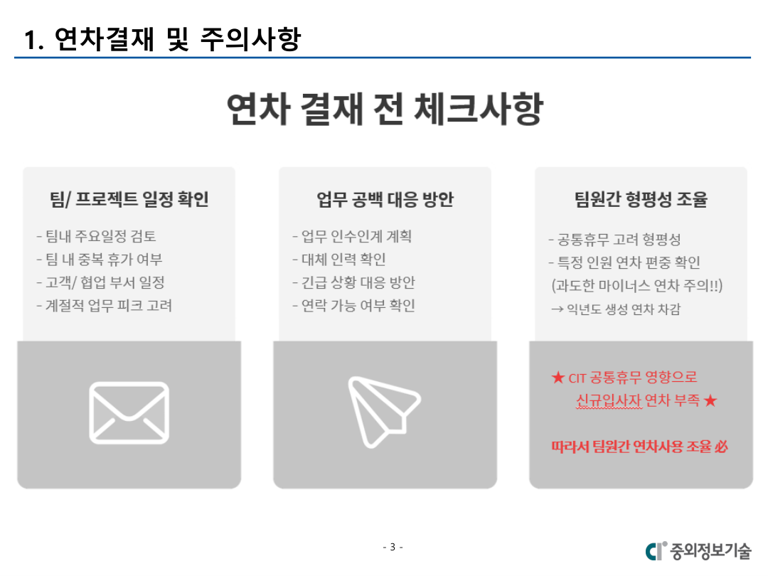

===== 페이지 4 =====


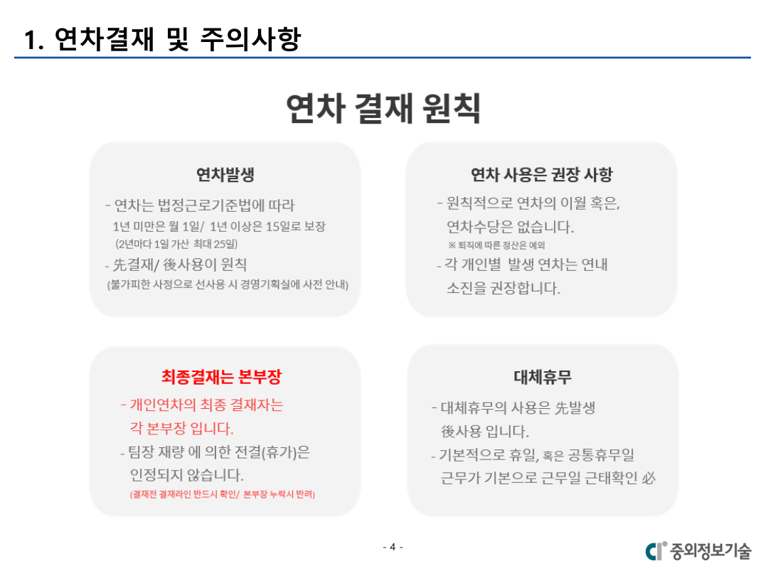

===== 페이지 5 =====


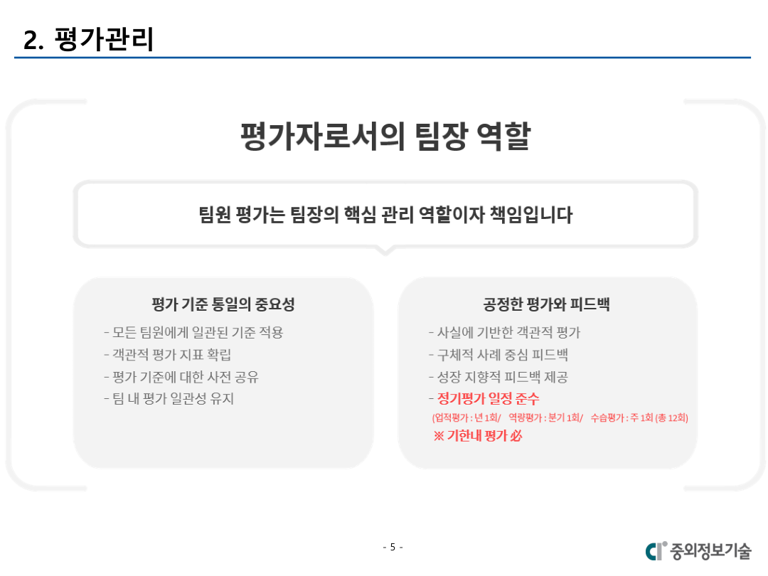

===== 페이지 6 =====


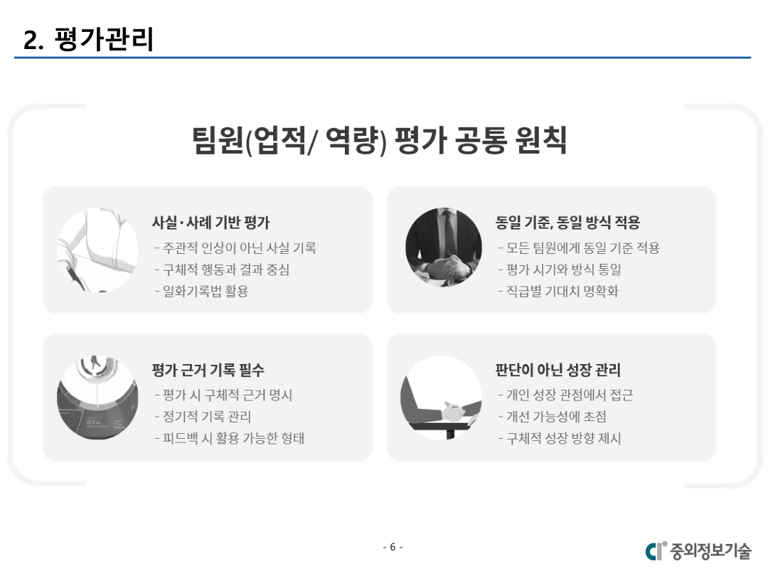

===== 페이지 7 =====


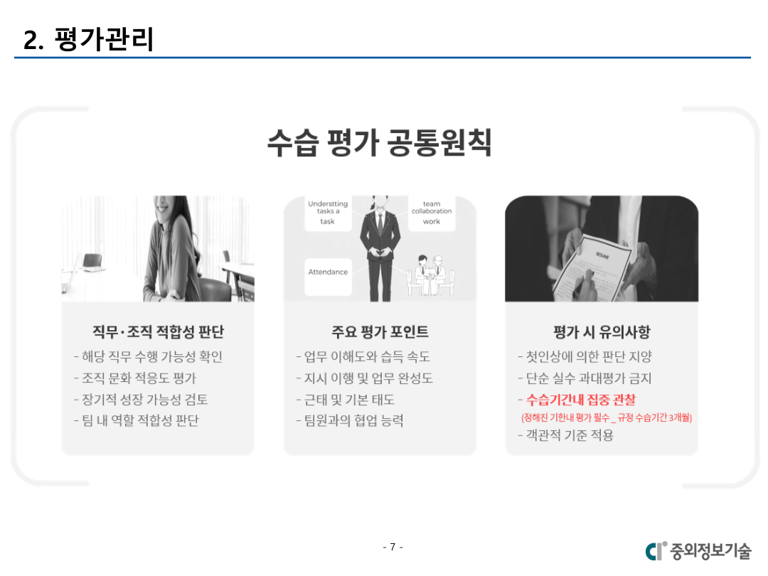

===== 페이지 8 =====


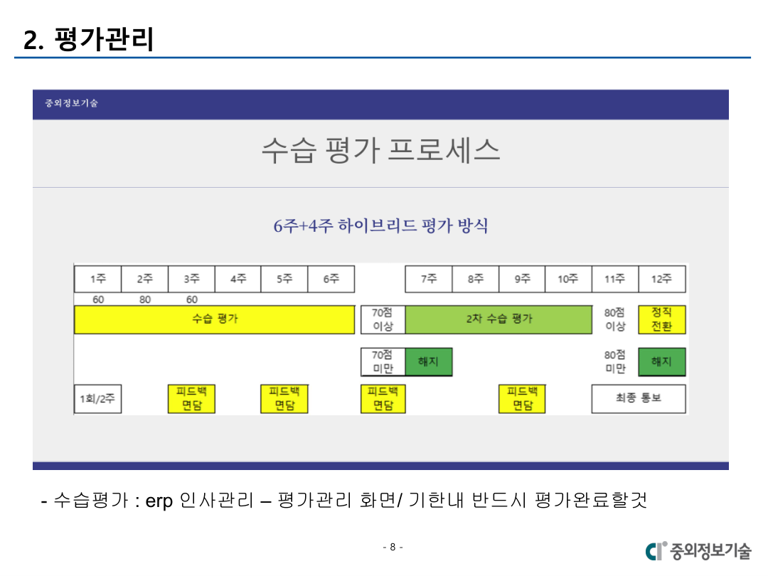

In [5]:
from IPython.display import display
from PIL import Image

SHOW_PAGES = [3, 4, 5, 6, 7, 8]
for number in SHOW_PAGES:
    if number <= len(pages):
        print(f"===== 페이지 {number} =====")
        im = Image.open(pages[number-1]["image"])
        display(im.resize((768, round(768*im.height/im.width))))

## Cell 6 — LangChain Vision LLM으로 각 슬라이드 설명 생성

슬라이드에 포함된 정책, 빨간 주의 문구, 표와 흐름도 분기를 검색 가능하도록 상세한 한국어 설명으로 변환합니다. 설명은 원본과 동일한 내용만 기록하고, 수습평가의 **6주/4주, 70/80점 등 수치 조건**을 원본 이미지로 검증합니다. 전체 9페이지 이미지에 API 요청이 발생합니다.

In [6]:
import base64
from langchain_openai import ChatOpenAI
from langchain_core.messages import HumanMessage, SystemMessage

vision = ChatOpenAI(model=CHAT_MODEL, temperature=0)

def image_data_uri(path):
    with open(path, "rb") as f:
        encoded = base64.b64encode(f.read()).decode("ascii")
    return "data:image/png;base64," + encoded

def summarize_slide(page):
    prompt = (
        f"이 이미지는 회사 FY26 연차사용 및 평가관리 가이드의 {page['page']}페이지입니다. "
        "보이는 제목, 항목, 규정, 일정, 숫자, 빨간 강조문구를 한국어로 정리하세요. "
        "표와 플로우차트는 분기 조건과 순서를 명시하세요. "
        "화면에 읽히지 않는 부분은 '판독 불가'라고 쓰고 추측하지 마세요. "
        "외부 법규나 일반 HR 관행을 추가하지 마세요."
    )
    msg = HumanMessage(content=[{"type":"text", "text":prompt},
                                {"type":"image_url", "image_url":{"url":image_data_uri(page['image'])}}])
    return vision.invoke([SystemMessage(content="당신은 사내 슬라이드 문서 분석 담당자입니다. 원문 충실도를 최우선으로 하세요."),msg]).content

slide_summaries = {}
for page in pages:
    slide_summaries[page["page"]] = summarize_slide(page)
    print(f"p.{page['page']} 요약 생성 완료 ({len(slide_summaries[page['page']])}자)")

p.1 요약 생성 완료 (198자)
p.2 요약 생성 완료 (101자)
p.3 요약 생성 완료 (315자)
p.4 요약 생성 완료 (323자)
p.5 요약 생성 완료 (307자)
p.6 요약 생성 완료 (384자)
p.7 요약 생성 완료 (379자)
p.8 요약 생성 완료 (391자)
p.9 요약 생성 완료 (5자)


## Cell 7 — PDF 텍스트 + Vision 설명 확인

이미지 설명과 PDF 내 텍스트를 비교해 내용 누락이나 환각이 없는지 검토합니다. 8페이지 프로세스의 숫자/분기, 4페이지 결재 원칙은 특히 중요한 확인 대상입니다.

In [7]:
for p in pages:
    if p["page"] in (4, 8):
        print("\n", "="*20, "페이지", p["page"], "="*20)
        print("PDF 텍스트:", p["text"][:600])
        print("Vision 요약:", slide_summaries[p["page"]][:1800])


 ==================== 페이지 4 ====================
PDF 텍스트: 1. 연차결재및주의사항





                                                                                        - 4 -
Vision 요약: ### 1. 연차결재 및 주의사항

#### 연차 결재 원칙

- **연차발생**
  - 연차는 법정근로기준법에 따라 1년 미만은 월 1일, 1년 이상은 15일로 보장
  - (2년마다 1개월 기준 최대 25일)

- **선결재/후사용 원칙**
  - (불가피한 사정으로 선사용 시 경영기획실에 사전 안내)

#### 최종결재는 본부장

- 개인연차의 최종 결재자는 각 본부장임.
- 팀장 재량에 의한 결정(휴가는 인정되지 않음).

#### 대체휴무

- 대체휴무의 사용은 선발생 후사용임.
- 기본적으로 휴일, 혹은 공동공무일 근무가 기준으로 근무 확인 필요.

판독 불가.

 ==================== 페이지 8 ====================
PDF 텍스트: 2. 평가관리





   - 수습평가: erp 인사관리– 평가관리화면/ 기한내반드시평가완료할것


                                                                                        - 8 -
Vision 요약: ### 2. 평가관리

#### 수습 평가 프로세스
- **6주 + 4주 하이브리드 평가 방식**

| 주차 | 1주 | 2주 | 3주 | 4주 | 5주 | 6주 | 7주 | 8주 | 9주 | 10주 | 11주 | 12주 |
|------|------|------|------|------|------|------|------|------|------|-------|-------|-------|
| 점수 | 60   | 80   | 60   |      |      |      | 70

## Cell 8 — 검색용 자식 문서와 원본 부모 문서 구축

LangChain `MultiVectorRetriever`의 원리를 직접 확인합니다.

- **Child(Document)**: 임베딩할 페이지별 추출 텍스트와 슬라이드 요약. `doc_id`를 부여합니다.
- **Parent(Document)**: 검색 뒤 LLM에 전달할 페이지 원문, 전체 페이지 이미지 경로, 페이지 번호를 유지합니다.
- 검색 결과는 자식 벡터 문서가 아니라 동일한 `doc_id`에 대응하는 **페이지 단위 원본 부모 문서**가 됩니다.

긴 텍스트에는 LangChain 청킹을 사용합니다. 텍스트가 비어 있어도 슬라이드 요약이 검색을 지원합니다.

In [8]:
import uuid
from langchain_text_splitters import RecursiveCharacterTextSplitter

splitter = RecursiveCharacterTextSplitter(chunk_size=900, chunk_overlap=120)
child_docs, parent_items = [], []
for p in pages:
    parent_id = str(uuid.uuid4())
    parent = Document(
        page_content=(p["text"] + "\n\n[슬라이드 설명]\n" + slide_summaries[p["page"]]).strip(),
        metadata={"doc_id": parent_id, "page": p["page"], "image_path": p["image"],
                  "source": pdf_path.name, "type":"page"}
    )
    parent_items.append((parent_id, parent))
    for piece in splitter.split_text(p["text"]):
        if piece.strip():
            child_docs.append(Document(page_content=f"[PDF 텍스트 p.{p['page']}] {piece}",
                                       metadata={"doc_id": parent_id, "page": p["page"], "modality":"text"}))
    child_docs.append(Document(page_content=f"[슬라이드 이미지 설명 p.{p['page']}] {slide_summaries[p['page']]}",
                               metadata={"doc_id": parent_id, "page": p["page"], "modality":"vision_summary"}))
print("자식 문서:",len(child_docs), "부모 문서:",len(parent_items))

자식 문서: 18 부모 문서: 9


## Cell 9 — Chroma와 MultiVectorRetriever 색인 생성

**잘못된 이미지 경로를 임베딩하지 않고 실제 이미지의 의미를 설명하는 텍스트를 임베딩**합니다. 부모 문서는 `InMemoryStore`에 저장하며, 수업 실습 중 런타임이 재시작되면 다시 만들어야 합니다. `id_key='doc_id'`는 검색된 자식과 부모를 연결하는 열쇠입니다.

In [9]:
from langchain_openai import OpenAIEmbeddings
from langchain_chroma import Chroma
from langchain_core.stores import InMemoryStore
from langchain_classic.retrievers.multi_vector import MultiVectorRetriever

embedding = OpenAIEmbeddings(model=EMBED_MODEL)
vectorstore = Chroma(collection_name="fy26_hr_slide_mmrag", embedding_function=embedding)
docstore = InMemoryStore()
retriever = MultiVectorRetriever(vectorstore=vectorstore, docstore=docstore,
                                  id_key="doc_id", search_kwargs={"k": 8})
vectorstore.add_documents(child_docs, ids=[str(uuid.uuid4()) for _ in child_docs])
docstore.mset(parent_items)
print("색인 구축 완료: 부모",len(parent_items),"자식",len(child_docs))

색인 구축 완료: 부모 9 자식 18


## Cell 10 — 근거 페이지 검색 실험

모델 답변 전에 검색된 **페이지 번호**가 적절한지 확인합니다. 예를 들어 연차결재는 3~4페이지, 수습평가 흐름도는 7~8페이지가 검색되는지 관찰합니다.

In [10]:
search_questions = [
    "팀장이 연차를 결재하기 전에 확인할 사항은 무엇인가요?",
    "연차의 최종 결재권자와 대체휴무 사용 원칙은?",
    "수습평가 6주+4주 프로세스에서 점수별 처리 흐름은?"
]
for q in search_questions:
    hits = retriever.invoke(q)
    print("\n질문:",q)
    print("검색 페이지:",[d.metadata["page"] for d in hits])


질문: 팀장이 연차를 결재하기 전에 확인할 사항은 무엇인가요?
검색 페이지: [2, 4, 3, 5, 7]

질문: 연차의 최종 결재권자와 대체휴무 사용 원칙은?
검색 페이지: [4, 3, 2, 1]

질문: 수습평가 6주+4주 프로세스에서 점수별 처리 흐름은?
검색 페이지: [8, 6, 7, 5, 2]


## Cell 11 — 검색한 텍스트와 원본 슬라이드 이미지를 멀티모달 메시지로 조립

검색 결과 페이지의 텍스트뿐 아니라 **원본 슬라이드 이미지 자체**를 Vision LLM에 다시 전달합니다. 페이지별 출처를 `p.N` 형식으로 명시하고, 문서에 없는 질문에는 답변을 보류하도록 제한합니다. 이미지 전송 개수는 비용 조절을 위해 기본 4페이지로 제한합니다.

In [11]:
MAX_CONTEXT_PAGES = 4

def build_messages(question, docs):
    docs = docs[:MAX_CONTEXT_PAGES]
    body = ["아래 제공된 FY26 사내 가이드의 근거만 활용해 한국어로 답변하세요. 각 주장에 (p.페이지) 출처를 표시하세요. "
            "표/도표의 분기조건은 원본 이미지를 직접 확인하세요. 근거가 없으면 문서에서 확인할 수 없다고 답하세요. "
            "일반 법률 조언이나 외부 규정을 섞지 마세요.", "\n질문: " + question]
    content = []
    for d in docs:
        page_no = d.metadata["page"]
        body.append(f"\n[원본 {page_no}페이지]\n{d.page_content[:4500]}")
    content.append({"type":"text", "text":"\n".join(body)})
    for d in docs:
        content.append({"type":"text", "text":f"다음은 {d.metadata['page']}페이지의 원본 슬라이드입니다."})
        content.append({"type":"image_url", "image_url":{"url":image_data_uri(d.metadata["image_path"])}})
    return [SystemMessage(content="당신은 사내 문서 기반 RAG QA 도우미입니다. 인용 근거와 신중한 판단을 최우선으로 합니다."),
            HumanMessage(content=content)]

print("프롬프트 생성 함수 준비 완료")

프롬프트 생성 함수 준비 완료


## Cell 12 — LangChain 기반 Multimodal RAG 질의응답

1) Retriever로 관련 페이지 검색 → 2) 페이지 원문과 이미지로 메시지 생성 → 3) LangChain `ChatOpenAI.invoke`로 답변 생성 → 4) 검색 페이지를 함께 출력합니다. **단순 이미지 캡션 검색**이 아니라, 검색 후 실제 이미지를 다시 읽는 방식입니다.

In [14]:
def ask_fy26(question):
    docs = retriever.invoke(question)
    if not docs:
        return {"question": question, "answer":"관련 페이지를 찾지 못했습니다.", "pages":[]}
    docs = docs[:MAX_CONTEXT_PAGES]
    reply = vision.invoke(build_messages(question, docs))
    return {"question":question, "answer":reply.content, "pages":[d.metadata["page"] for d in docs]}

result = ask_fy26("수습평가 6주+4주 프로세스에서 점수별 처리 흐름은?") # 연차의 최종 결재권자와 대체휴무 사용 원칙은? 팀장이 연차결재 전에 반드시 확인해야 할 사항을 설명해 주세요
print("질문:", result["question"])
print("답변:\n",result["answer"])
print("근거 후보 페이지:",result["pages"])

질문: 수습평가 6주+4주 프로세스에서 점수별 처리 흐름은?
답변:
 수습평가 6주 + 4주 프로세스에서 점수별 처리 흐름은 다음과 같습니다:

- **1주**: 60점
- **2주**: 80점
- **3주**: 60점
- **4주**: (점수 없음)
- **5주**: (점수 없음)
- **6주**: (점수 없음)
- **7주**: 70점 이상
- **8주**: 80점 이상
- **9주**: 80점 미만 → 해지
- **10주**: (점수 없음)
- **11주**: (점수 없음)
- **12주**: 최종 통보 (p.8)

이와 같은 점수 흐름에 따라 수습평가가 진행됩니다.
근거 후보 페이지: [8, 6, 7, 5]


## Cell 13 — FY26 문서 맞춤 평가 질문

원본 가이드에 답이 있는 질문과 없는 질문을 섞어 **retrieval / visual grounding / abstention** 능력을 시험합니다. 모델 출력은 사람이 원본 페이지와 대조해 검토하세요. 여러 차례 실행하면 API 비용이 발생합니다.

In [ ]:
fy26_questions = [
    "연차 결재 전 팀/프로젝트 일정과 업무 공백 관점에서 확인할 항목은?",
    "개인연차 최종 결재권자와 팀장이 알아야 할 제한 사항은?",
    "팀장이 업적·역량 평가를 진행할 때 객관성을 확보하는 방법은?",
    "수습평가에서 직무·조직 적합성을 평가하는 기준은?",
    "8페이지 수습평가 프로세스의 6주+4주 단계와 70점, 80점 기준은?",
    "문서에 회사의 2027년 연차수당 금액이 명시되어 있나요?"
]
# 과도한 호출을 방지하기 위해 기본 2개만 실행합니다. 전체 테스트 시 숫자 변경
for q in fy26_questions[:2]:
    out = ask_fy26(q)
    print("\n질문:", q, "\n답변:",out["answer"], "\n검색 페이지:",out["pages"],"\n")

## Cell 14 — 검색 증거 점검과 실습 평가 기준

**검증표**

| 질문 유형 | 기대 참조 페이지 | 확인할 사항 |
|---|---|---|
| 연차 승인 전 체크 | 3 | 팀 일정, 업무 공백, 형평성 |
| 연차 발생/결재/대체휴무 | 4 | 최종 결재권자, 사용 원칙 |
| 평가자 역할과 주기 | 5 | 객관성 및 정기평가 |
| 업적·역량 평가 | 6 | 사실·사례·근거·성장 |
| 수습평가 주요 기준 | 7 | 업무 이해도, 지시 이행, 태도, 협업 |
| 수습평가 흐름도 | 8 | 6주+4주, 70/80점 분기, ERP 기한 |
| 문서 외 정보 | 해당 없음 | 임의 생성 없이 보류 |

**실습 과제:** `search_kwargs['k']`와 `MAX_CONTEXT_PAGES`를 바꾸고, 검색 페이지 재현율과 답변의 페이지 출처 정확도를 비교해 보세요. 요약이나 답변이 틀릴 수 있으므로 숫자 기준, 인사 조치 등의 내용은 원본 문서 및 담당자 확인을 우선합니다.

## 기술 요약 및 주의사항

- `PyMuPDF`: 슬라이드 전체를 PNG로 렌더링하고 텍스트를 추출합니다. 장표의 도형 속 글자는 시각 경로로 보완됩니다.
- `ChatOpenAI`: 각 장표의 이미지 설명을 생성하고 답변할 때 검색된 원본 이미지를 재확인합니다.
- `Chroma`: 페이지 텍스트와 이미지 요약을 함께 임베딩합니다.
- `MultiVectorRetriever`: 여러 자식 임베딩을 각 장표의 하나의 부모 문서로 연결합니다.
- **제약**: 가이드 9페이지 대상으로 설계됐습니다. 시각 설명은 LLM 결과이므로 중요한 수치/조건에는 사람 검증이 필요합니다. 실제 API 사용에는 외부 전송 보안 검토 및 과금이 필요합니다.
- Colab에서 위에서부터 차례대로 실행하세요. 패키지 설치 후 ImportError가 발생하면 런타임 재시작 후 Cell 2부터 실행하세요.